# NGC 253: H II-region and SNR/shock first-pass catalogue

This notebook keeps the original **astrodendro + Photutils deblending** workflow.

Main choices:

- Hα, [O III], and [S II] are detected together in one branch.
- The detection map uses one global noise value per line.
- Planetary nebulae are not handled here.
- Astrodendro finds reliable initial emission structures.
- `photutils.deblend_sources` separates blended peaks inside those structures.
- Final masks are trimmed to the isophote containing 90% of the positive local-background-subtracted detection flux.
- No segmented region is rejected. Quality columns are only inspection flags.
- Low Hα surface brightness is replaced by a local Hα contrast measurement.
- Missing BPT information is kept separate from BPT-confirmed H II candidates.


In [9]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

from astropy.io import fits
from astropy.wcs import WCS
from astrodendro import Dendrogram
from photutils.segmentation import SegmentationImage, deblend_sources
from skimage.measure import regionprops_table
from skimage.segmentation import find_boundaries
from tqdm.notebook import tqdm


## 1. Configuration

In [10]:
DATA_FITS = Path("/Users/golta/Desktop/Uni/Thesis/ADP.2025-07-06T07_52_11.876.fits")
OUTPUT_DIR = Path("./results_photutils")

pix_scale = 0.2
psf_fwhm_arcsec = 0.85
psf_fwhm_pix = psf_fwhm_arcsec / pix_scale

# Boundary refinement
BOUNDARY_FLUX_FRACTION = 0.90
BOUNDARY_ANNULUS_WIDTH = 5

# Local background extraction
ANNULUS_INNER_FACTOR = 0.8
ANNULUS_OUTER_FACTOR = 1.4
MIN_ANNULUS_PIX = 30

# Measurement/classification thresholds
LINE_SN_MIN = 3.0
HA_CONTRAST_MIN = 3.0
SII_HA_HII_MAX = 0.35
SII_HA_SHOCK_MIN = 0.40
OI_HA_SHOCK_MIN = 0.05
MAX_ELONGATION = 5.0
LARGE_REGION_QUANTILE = 0.98


## 2. Small helper functions

In [11]:
def percentile_norm(img, pmin=1, pmax=99):
    x = np.array(img, dtype=float, copy=True)
    x[~np.isfinite(x)] = np.nan
    lo, hi = np.nanpercentile(x, [pmin, pmax])
    return np.clip((x - lo) / (hi - lo), 0, 1)


def clean_map(x):
    y = np.array(x, dtype=float, copy=True)
    y[~np.isfinite(y)] = 0.0
    y[y < 0] = 0.0
    return y


def get_label_array(label_obj):
    if isinstance(label_obj, np.ndarray):
        arr = label_obj
    elif hasattr(label_obj, "data"):
        arr = label_obj.data
    else:
        arr = np.asarray(label_obj)
    return np.asarray(arr, dtype=np.int32)


def count_regions(label_array):
    labels = np.asarray(label_array)
    return int(np.sum(np.unique(labels) > 0))


def safe_log10_ratio(num, den):
    num = np.asarray(num, dtype=float)
    den = np.asarray(den, dtype=float)
    out = np.full(np.broadcast(num, den).shape, np.nan, dtype=float)
    valid = np.isfinite(num) & np.isfinite(den) & (num > 0) & (den > 0)
    out[valid] = np.log10(num[valid] / den[valid])
    return out


## 3. Global-noise detection map

In [12]:
def global_noise(err, method="median"):
    err = np.asarray(err, dtype=float)
    values = err[np.isfinite(err) & (err > 0)]

    if method == "median":
        return np.nanmedian(values)
    if method == "rms":
        return np.sqrt(np.nanmedian(values**2))
    if method == "percentile":
        return np.nanpercentile(values, 60)
    return np.nanmean(values)


def det_map(ha, ha_err, oiii, oiii_err, sii, sii_err,
            snr_min=0.0, noise_method="median"):
    fluxes = [ha, oiii, sii]
    errors = [ha_err, oiii_err, sii_err]
    noises = [global_noise(err, noise_method) for err in errors]

    detection_sq = np.zeros_like(ha, dtype=float)

    for flux, noise in zip(fluxes, noises):
        snr = np.asarray(flux, dtype=float) / noise
        snr[~np.isfinite(snr)] = 0.0
        snr = np.clip(snr, 0, None)

        if snr_min > 0:
            snr[snr < snr_min] = 0.0

        detection_sq += snr**2

    return np.sqrt(detection_sq)


## 4. Astrodendro and Photutils segmentation

In [13]:
def comp_dendro(input_den, min_value, min_delta, min_npix):
    dendro = Dendrogram.compute(
        input_den,
        min_value=min_value,
        min_delta=min_delta,
        min_npix=min_npix,
    )

    labels = np.zeros(input_den.shape, dtype=np.int32)
    for region_id, leaf in enumerate(dendro.leaves, start=1):
        labels[leaf.get_mask()] = region_id

    print(f"Astrodendro leaves: {len(dendro.leaves)}")
    return labels, dendro


def conv(labels, detection, n_pixels, smooth_sigma,
         smooth_threshold, n_levels, contrast):
    # Keep the original idea: mildly smooth the binary dendrogram support,
    # join touching support pixels, then let Photutils deblend the structures.
    binary_mask = labels > 0
    smooth_mask = ndi.gaussian_filter(
        binary_mask.astype(float), sigma=smooth_sigma
    ) > smooth_threshold

    connected_labels, _ = ndi.label(smooth_mask)
    segmentation = SegmentationImage(connected_labels.astype(np.int32))

    deblended = deblend_sources(
        clean_map(detection),
        segmentation,
        n_pixels,
        n_levels=n_levels,
        contrast=contrast,
        progress_bar=False,
    )

    labels_final = get_label_array(deblended)
    print(f"Photutils deblended regions: {count_regions(labels_final)}")
    return labels_final


def refine_boundaries(labels, detection, flux_fraction=0.90, annulus_width=5):
    # For each Photutils region, keep the brightest connected isophote that
    # contains the requested fraction of positive local-background-subtracted
    # detection flux. No region is rejected.
    labels = np.asarray(labels, dtype=np.int32)
    detection = np.asarray(detection, dtype=float)
    refined = np.zeros_like(labels)
    objects = ndi.find_objects(labels)
    ny, nx = labels.shape

    for region_id, base_slice in enumerate(objects, start=1):
        if base_slice is None:
            continue

        yslice, xslice = base_slice
        y0 = max(yslice.start - annulus_width, 0)
        y1 = min(yslice.stop + annulus_width, ny)
        x0 = max(xslice.start - annulus_width, 0)
        x1 = min(xslice.stop + annulus_width, nx)
        slc = np.s_[y0:y1, x0:x1]

        local_labels = labels[slc]
        local_detection = detection[slc]
        mask = local_labels == region_id

        annulus = ndi.binary_dilation(mask, iterations=annulus_width)
        annulus &= ~mask
        annulus &= local_labels == 0

        bg_values = local_detection[annulus]
        bg_values = bg_values[np.isfinite(bg_values)]
        background = np.nanmedian(bg_values) if bg_values.size else 0.0

        positive = np.clip(local_detection - background, 0, None)
        region_values = positive[mask]
        total_flux = np.nansum(region_values)

        if total_flux <= 0:
            keep = mask
        else:
            sorted_values = np.sort(region_values)[::-1]
            cumulative = np.cumsum(sorted_values)
            index = np.searchsorted(cumulative, flux_fraction * total_flux)
            index = min(index, sorted_values.size - 1)
            level = sorted_values[index]
            keep = mask & (positive >= level)

            # Keep the connected component containing the brightest pixel.
            peak_index = np.nanargmax(np.where(mask, local_detection, -np.inf))
            peak_y, peak_x = np.unravel_index(peak_index, mask.shape)
            components, _ = ndi.label(keep)
            component_id = components[peak_y, peak_x]

            if component_id > 0:
                keep = components == component_id
            else:
                keep = mask

            keep = ndi.binary_fill_holes(keep)

        refined_crop = refined[slc]
        refined_crop[keep] = region_id
        refined[slc] = refined_crop

    return refined

def plot_segmentation_result(run_name, result, detection):
    base = percentile_norm(detection)
    dendro_data = result["dendro_data"]
    deblend_data = result["labels_data"]

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    axes[0].imshow(base, origin="lower")
    axes[0].contour(dendro_data > 0, levels=[0.5], colors="red", linewidths=0.7)
    axes[0].set_title(
        f"{run_name}: astrodendro\n{result['n_dendro_regions']} leaves"
    )

    axes[1].imshow(base, origin="lower")
    axes[1].contour(deblend_data > 0, levels=[0.5], colors="red", linewidths=0.7)
    axes[1].set_title(
        f"{run_name}: Photutils\n{result['n_conv_regions']} regions"
    )

    for ax in axes:
        ax.set_xticks([])
        ax.set_yticks([])

    plt.tight_layout()
    plt.show()


## 5. Region measurements and local background

In [14]:
def make_segmentation_qa(labels_data, detection, wcs, pix_scale):
    labels = np.asarray(labels_data, dtype=np.int32)
    detection = np.asarray(detection, dtype=float)

    props = regionprops_table(
        labels,
        properties=(
            "label", "area", "centroid", "bbox",
            "axis_major_length", "axis_minor_length", "eccentricity"
        ),
    )
    df = pd.DataFrame(props)

    region_ids = df["label"].to_numpy(dtype=int)
    y = df["centroid-0"].to_numpy(float)
    x = df["centroid-1"].to_numpy(float)
    ra, dec = wcs.wcs_pix2world(x, y, 0)

    min_y = df["bbox-0"].to_numpy(int)
    min_x = df["bbox-1"].to_numpy(int)
    max_y = df["bbox-2"].to_numpy(int)
    max_x = df["bbox-3"].to_numpy(int)

    det_peak = []
    det_median = []
    det_p90 = []

    for region_id in region_ids:
        values = detection[labels == region_id]
        values = values[np.isfinite(values)]
        det_peak.append(np.nanmax(values))
        det_median.append(np.nanmedian(values))
        det_p90.append(np.nanpercentile(values, 90))

    npix = df["area"].to_numpy(int)
    r_eq_pix = np.sqrt(npix / np.pi)
    major = df["axis_major_length"].to_numpy(float)
    minor = df["axis_minor_length"].to_numpy(float)
    elongation = np.divide(
        major, minor,
        out=np.full_like(major, np.nan),
        where=minor > 0,
    )

    ny, nx = labels.shape

    return pd.DataFrame({
        "region_id": region_ids,
        "npix": npix,
        "area_arcsec2": npix * pix_scale**2,
        "r_eq_pix": r_eq_pix,
        "r_eq_arcsec": r_eq_pix * pix_scale,
        "x": x,
        "y": y,
        "ra": ra,
        "dec": dec,
        "bbox_width": max_x - min_x,
        "bbox_height": max_y - min_y,
        "edge_touching": (
            (min_y == 0) | (min_x == 0) | (max_y == ny) | (max_x == nx)
        ),
        "major_axis_pix": major,
        "minor_axis_pix": minor,
        "elongation": elongation,
        "eccentricity": df["eccentricity"].to_numpy(float),
        "det_peak": det_peak,
        "det_median": det_median,
        "det_p90": det_p90,
    })


def make_local_annulus(labels_data, region_id, qa_lookup, label_slices,
                       inner_factor, outer_factor,
                       min_inner_pix=3, min_outer_pix=6, extra_pad=2):
    row = qa_lookup.loc[region_id]
    r_eq_pix = row["r_eq_pix"]

    inner_rad = int(np.ceil(max(inner_factor * r_eq_pix, min_inner_pix)))
    outer_rad = int(np.ceil(max(outer_factor * r_eq_pix, min_outer_pix)))
    outer_rad = max(outer_rad, inner_rad + 2)

    base_slice = label_slices[region_id - 1]
    if base_slice is None:
        return None, None, None

    yslice, xslice = base_slice
    ny, nx = labels_data.shape

    y0 = max(yslice.start - outer_rad - extra_pad, 0)
    y1 = min(yslice.stop + outer_rad + extra_pad, ny)
    x0 = max(xslice.start - outer_rad - extra_pad, 0)
    x1 = min(xslice.stop + outer_rad + extra_pad, nx)

    slc = np.s_[y0:y1, x0:x1]
    labels_crop = labels_data[slc]
    source_crop = labels_crop == region_id
    distance = ndi.distance_transform_edt(~source_crop)

    annulus_crop = (
        (distance > inner_rad)
        & (distance <= outer_rad)
        & (labels_crop == 0)
    )

    return source_crop, annulus_crop, slc


def robust_background_stats(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if values.size == 0:
        return np.nan, np.nan, np.nan, 0

    median = np.nanmedian(values)
    mad = np.nanmedian(np.abs(values - median))
    sigma = 1.4826 * mad

    if not np.isfinite(sigma) or sigma == 0:
        sigma = np.nanstd(values)

    median_error = 1.253 * sigma / np.sqrt(values.size)
    return median, sigma, median_error, values.size


def extract_region_fluxes(labels_data, region_id, qa_lookup, label_slices,
                          line_maps, line_err_maps,
                          inner_factor, outer_factor, min_annulus_pix=20):
    source_crop, annulus_crop, slc = make_local_annulus(
        labels_data,
        region_id,
        qa_lookup,
        label_slices,
        inner_factor,
        outer_factor,
    )

    if source_crop is None:
        return None

    n_src = int(np.sum(source_crop))
    n_ann = int(np.sum(annulus_crop))

    result = {
        "region_id": region_id,
        "n_src_pix": n_src,
        "n_ann_pix": n_ann,
        "flag_bad_annulus": n_ann < min_annulus_pix,
    }

    for line_name, image in line_maps.items():
        image_crop = image[slc]
        source_values = image_crop[source_crop]
        annulus_values = image_crop[annulus_crop]

        raw_flux = np.nansum(source_values)
        bg_level, bg_sigma, bg_level_err, _ = robust_background_stats(annulus_values)

        bg_flux = bg_level * n_src
        bg_flux_err = bg_level_err * n_src
        corr_flux = raw_flux - bg_flux

        err_crop = line_err_maps[line_name][slc]
        raw_err = np.sqrt(np.nansum(err_crop[source_crop] ** 2))
        corr_err = np.sqrt(raw_err**2 + bg_flux_err**2)

        result[f"{line_name}_raw_flux"] = raw_flux
        result[f"{line_name}_raw_err"] = raw_err
        result[f"{line_name}_raw_sn"] = raw_flux / raw_err if raw_err > 0 else np.nan

        result[f"{line_name}_bg_level"] = bg_level
        result[f"{line_name}_bg_sigma"] = bg_sigma
        result[f"{line_name}_bg_flux"] = bg_flux
        result[f"{line_name}_bg_flux_err"] = bg_flux_err
        result[f"{line_name}_bg_fraction"] = (
            bg_flux / raw_flux if raw_flux != 0 else np.nan
        )

        result[f"{line_name}_corr_flux"] = corr_flux
        result[f"{line_name}_corr_err"] = corr_err
        result[f"{line_name}_corr_sn"] = (
            corr_flux / corr_err if corr_err > 0 else np.nan
        )

    return result


In [15]:
def classify_bpt(log_nii_ha, log_oiii_hb):
    if not (np.isfinite(log_nii_ha) and np.isfinite(log_oiii_hb)):
        return "unclassified_BPT"

    kewley = 0.61 / (log_nii_ha - 0.47) + 1.19
    kauffmann = 0.61 / (log_nii_ha - 0.05) + 1.30

    if log_nii_ha < 0.05 and log_oiii_hb < kauffmann:
        return "HII_BPT_clean"
    if log_nii_ha < 0.47 and log_oiii_hb < kewley:
        return "HII_BPT_possible"
    return "non_HII_BPT"


def expand_slice(slc, image_shape, pad=40):
    yslice, xslice = slc
    ny, nx = image_shape[:2]
    return np.s_[
        max(yslice.start - pad, 0):min(yslice.stop + pad, ny),
        max(xslice.start - pad, 0):min(xslice.stop + pad, nx),
    ]


def show_source_annulus(image, source_crop, annulus_crop, slc,
                        labels_data=None, title="", pad=40):
    plot_slc = expand_slice(slc, image.shape, pad)
    image_view = image[plot_slc]

    source_view = np.zeros(image_view.shape[:2], dtype=bool)
    annulus_view = np.zeros(image_view.shape[:2], dtype=bool)

    y_offset = slc[0].start - plot_slc[0].start
    x_offset = slc[1].start - plot_slc[1].start
    height, width = source_crop.shape

    source_view[y_offset:y_offset + height, x_offset:x_offset + width] = source_crop
    annulus_view[y_offset:y_offset + height, x_offset:x_offset + width] = annulus_crop

    plt.figure(figsize=(8, 8))
    plt.imshow(image_view, origin="lower")

    if labels_data is not None:
        boundaries = find_boundaries(labels_data[plot_slc], mode="outer")
        plt.contour(boundaries, levels=[0.5], colors="white", linewidths=0.5, alpha=0.45)

    plt.contour(source_view, levels=[0.5], colors="lime", linewidths=2.0)
    if np.any(annulus_view):
        plt.contour(annulus_view, levels=[0.5], colors="red", linewidths=1.3)

    plt.title(title)
    plt.axis("off")
    plt.show()


## 6. Load MUSE line maps

In [16]:
hdul = fits.open(DATA_FITS, memmap=True)

ha = hdul["HA6562_FLUX"].data
hb = hdul["HB4861_FLUX"].data
oiii = hdul["OIII5006_FLUX"].data
nii = hdul["NII6583_FLUX"].data
sii6716 = hdul["SII6716_FLUX"].data
sii6730 = hdul["SII6730_FLUX"].data
sii = sii6716 + sii6730
oi = hdul["OI6300_FLUX"].data

ha_err = hdul["HA6562_FLUX_ERR"].data
hb_err = hdul["HB4861_FLUX_ERR"].data
oiii_err = hdul["OIII5006_FLUX_ERR"].data
nii_err = hdul["NII6583_FLUX_ERR"].data
sii6716_err = hdul["SII6716_FLUX_ERR"].data
sii6730_err = hdul["SII6730_FLUX_ERR"].data
sii_err = np.sqrt(sii6716_err**2 + sii6730_err**2)
oi_err = hdul["OI6300_FLUX_ERR"].data

header = hdul["HA6562_FLUX"].header
wcs = WCS(header)


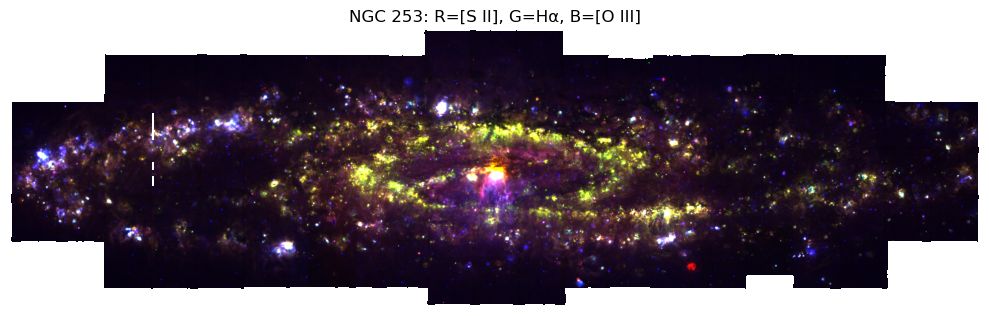

In [17]:
rgb = np.dstack([
    percentile_norm(sii),
    percentile_norm(ha),
    percentile_norm(oiii),
])

plt.figure(figsize=(10, 5))
plt.imshow(rgb, origin="lower")
plt.title("NGC 253: R=[S II], G=Hα, B=[O III]")
plt.axis("off")
plt.tight_layout()
plt.show()


## 7. Build the combined Hα + [O III] + [S II] detection map

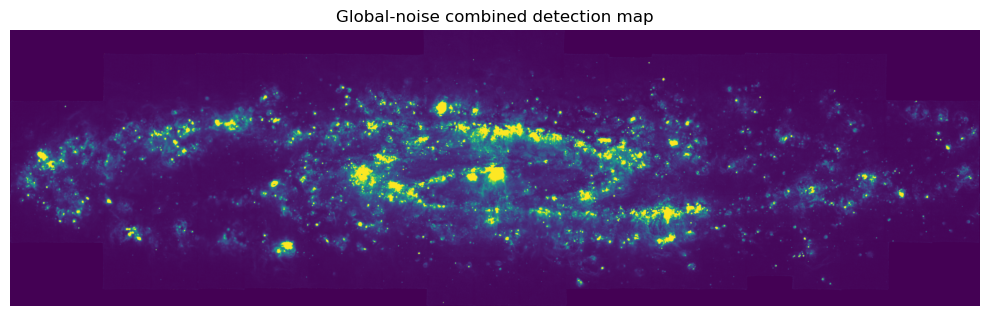

In [18]:
detection = det_map(
    ha, ha_err,
    oiii, oiii_err,
    sii, sii_err,
    snr_min=0.0,
    noise_method="median",
)

plt.figure(figsize=(10, 5))
plt.imshow(percentile_norm(detection), origin="lower")
plt.title("Global-noise combined detection map")
plt.axis("off")
plt.tight_layout()
plt.show()


## 8. Test segmentation parameters

In [19]:
# The runs move from permissive to conservative.
# Photutils contrast is kept at 0.001; the deblending minimum size is 100-150 pixels.
segmentation_runs = {
    "1": {
        "dendro": (20.0, 15.0, 100),
        "conv": (100, 1.0, 0.5, 32, 1e-3),
    },
    "2": {
        "dendro": (20.0, 20.0, 150),
        "conv": (100, 1.0, 0.5, 32, 1e-3),
    },
    "3": {
        "dendro": (25.0, 20.0, 150),
        "conv": (150, 1.0, 0.5, 32, 1e-3),
    },
    "4": {
        "dendro": (25.0, 25.0, 250),
        "conv": (150, 1.0, 0.5, 32, 1e-3),
    },
}


In [20]:
segmentation_results = {}

for run_name, parameters in segmentation_runs.items():
    min_value, min_delta, min_npix = parameters["dendro"]
    n_pixels, smooth_sigma, smooth_threshold, n_levels, contrast = parameters["conv"]

    print(f"\nRunning {run_name}")

    dendro_labels, dendro = comp_dendro(
        detection, min_value, min_delta, min_npix
    )
    deblended_labels = conv(
        dendro_labels,
        detection,
        n_pixels,
        smooth_sigma,
        smooth_threshold,
        n_levels,
        contrast,
    )

    segmentation_results[run_name] = {
        "params": parameters,
        "dendro": dendro,
        "dendro_data": dendro_labels,
        "labels_data": deblended_labels,
        "n_dendro_regions": count_regions(dendro_labels),
        "n_conv_regions": count_regions(deblended_labels),
    }



Running 1
Astrodendro leaves: 2013


Photutils deblended regions: 2059

Running 2
Astrodendro leaves: 1438


Photutils deblended regions: 1631

Running 3
Astrodendro leaves: 1361


Photutils deblended regions: 1374

Running 4
Astrodendro leaves: 935
Photutils deblended regions: 1067


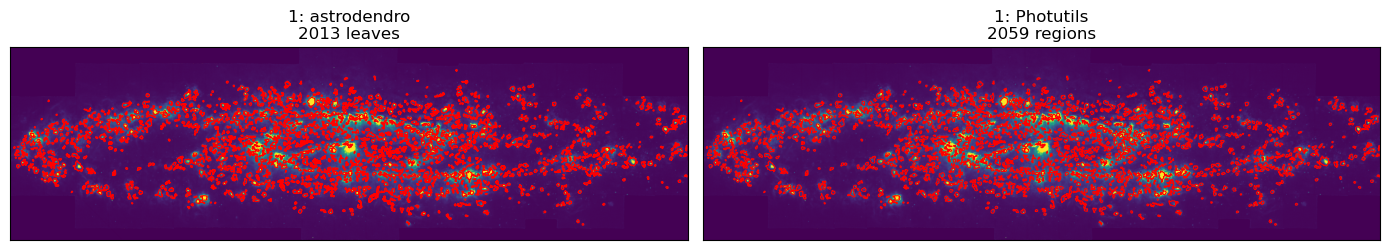

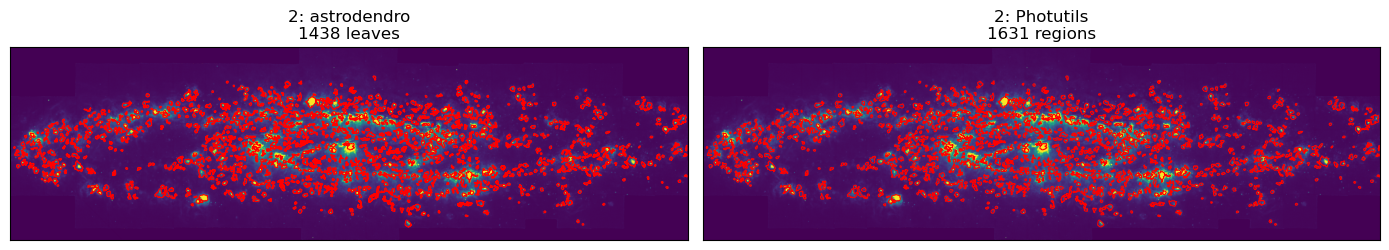

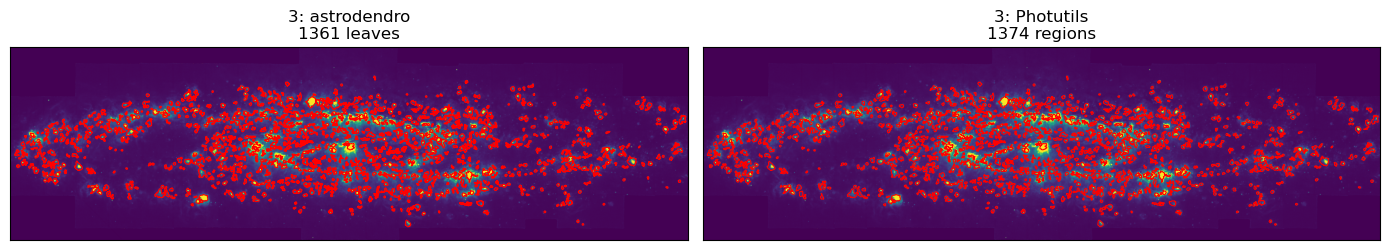

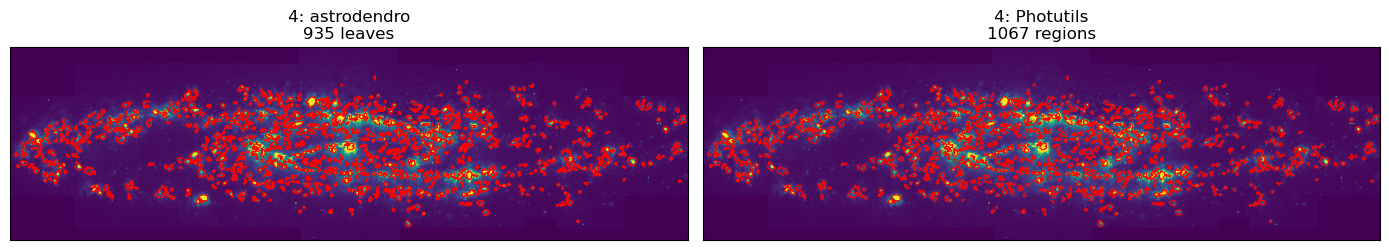

In [21]:
for run_name, result in segmentation_results.items():
    plot_segmentation_result(run_name, result, detection)


In [22]:
segmentation_summary = pd.DataFrame([
    {
        "run_name": run_name,
        "n_dendro_regions": result["n_dendro_regions"],
        "n_photutils_regions": result["n_conv_regions"],
        "dendro_min_value": result["params"]["dendro"][0],
        "dendro_min_delta": result["params"]["dendro"][1],
        "dendro_min_npix": result["params"]["dendro"][2],
        "deblend_n_pixels": result["params"]["conv"][0],
        "smooth_sigma": result["params"]["conv"][1],
        "smooth_threshold": result["params"]["conv"][2],
        "deblend_n_levels": result["params"]["conv"][3],
        "deblend_contrast": result["params"]["conv"][4],
    }
    for run_name, result in segmentation_results.items()
])

segmentation_summary


,run_name,n_dendro_regions,n_photutils_regions,dendro_min_value,dendro_min_delta,dendro_min_npix,deblend_n_pixels,smooth_sigma,smooth_threshold,deblend_n_levels,deblend_contrast
0,1,2013,2059,20.0,15.0,100,100,1.0,0.5,32,0.001
1,2,1438,1631,20.0,20.0,150,100,1.0,0.5,32,0.001
2,3,1361,1374,25.0,20.0,150,150,1.0,0.5,32,0.001
3,4,935,1067,25.0,25.0,250,150,1.0,0.5,32,0.001


## 9. Select a run and refine its boundaries

In [23]:
selected_run = "3"
selected_segmentation_params = segmentation_results[selected_run]["params"]
labels_photutils = segmentation_results[selected_run]["labels_data"]

labels_data = refine_boundaries(
    labels_photutils,
    detection,
    flux_fraction=BOUNDARY_FLUX_FRACTION,
    annulus_width=BOUNDARY_ANNULUS_WIDTH,
)

print("Selected run:", selected_run)
print("Photutils regions:", count_regions(labels_photutils))
print("Final refined regions:", count_regions(labels_data))
print("Parameters:", selected_segmentation_params)


Selected run: 3
Photutils regions: 1374
Final refined regions: 1374
Parameters: {'dendro': (25.0, 20.0, 150), 'conv': (150, 1.0, 0.5, 32, 0.001)}


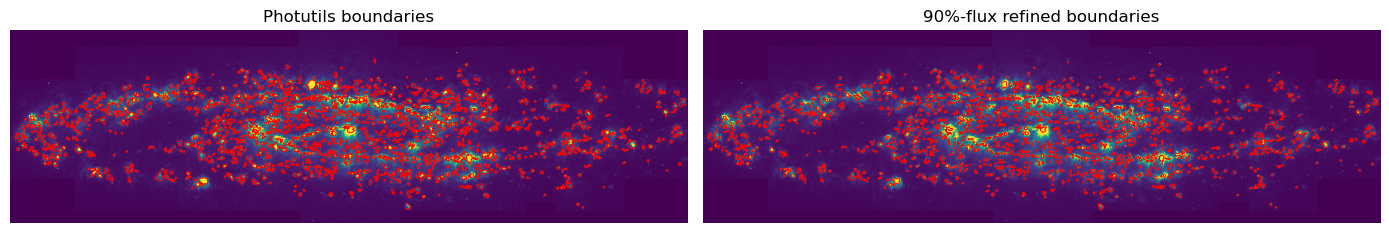

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
base = percentile_norm(detection)

axes[0].imshow(base, origin="lower")
axes[0].contour(labels_photutils > 0, levels=[0.5], colors="red", linewidths=0.6)
axes[0].set_title("Photutils boundaries")

axes[1].imshow(base, origin="lower")
axes[1].contour(labels_data > 0, levels=[0.5], colors="red", linewidths=0.6)
axes[1].set_title(f"{BOUNDARY_FLUX_FRACTION:.0%}-flux refined boundaries")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


## 10. Morphology and detection measurements — inspection only

In [25]:
qa2 = make_segmentation_qa(labels_data, detection, wcs, pix_scale)

large_npix_cut = qa2["npix"].quantile(LARGE_REGION_QUANTILE)
qa2["flag_edge_touching"] = qa2["edge_touching"]
qa2["flag_very_elongated"] = qa2["elongation"] > MAX_ELONGATION
qa2["flag_very_large"] = qa2["npix"] > large_npix_cut

print("Total regions:", len(qa2))
print("Edge-touching:", int(qa2["flag_edge_touching"].sum()))
print("Very elongated:", int(qa2["flag_very_elongated"].sum()))
print("Very large:", int(qa2["flag_very_large"].sum()))

qa2[["npix", "r_eq_arcsec", "elongation", "det_peak", "det_median"]].describe()


Total regions: 1374
Edge-touching: 0
Very elongated: 3
Very large: 28


,npix,r_eq_arcsec,elongation,det_peak,det_median
count,1374.000000,1374.000000,1361.000000,1374.000000,1374.000000
mean,319.546579,1.869677,1.705333,483.362743,139.871010
std,291.622343,0.757179,0.591848,2257.161258,224.203208
min,1.000000,0.112838,1.008777,25.089971,25.089971
25%,147.000000,1.368087,1.284263,91.247299,53.570947
50%,227.000000,1.700075,1.543233,175.751742,84.239987
75%,374.750000,2.184368,1.977201,386.709830,146.260157
max,2751.000000,5.918346,5.978049,70061.064429,4378.948222


## 11. Local background/DIG subtraction and integrated line fluxes

In [26]:
label_slices = ndi.find_objects(labels_data)
qa_lookup = qa2.set_index("region_id")

line_maps = {
    "ha": ha,
    "hb": hb,
    "oiii": oiii,
    "nii": nii,
    "sii": sii,
    "oi": oi,
}
line_err_maps = {
    "ha": ha_err,
    "hb": hb_err,
    "oiii": oiii_err,
    "nii": nii_err,
    "sii": sii_err,
    "oi": oi_err,
}


In [27]:
rows = []

for region_id in tqdm(qa2["region_id"].values):
    row = extract_region_fluxes(
        labels_data,
        region_id,
        qa_lookup,
        label_slices,
        line_maps,
        line_err_maps,
        inner_factor=ANNULUS_INNER_FACTOR,
        outer_factor=ANNULUS_OUTER_FACTOR,
        min_annulus_pix=MIN_ANNULUS_PIX,
    )
    if row is not None:
        rows.append(row)

flux_cat = pd.DataFrame(rows)
cat = qa2.merge(flux_cat, on="region_id", how="left")

print("Morphology rows:", len(qa2))
print("Flux rows:", len(flux_cat))
print("Merged catalogue:", len(cat))


  0%|          | 0/1374 [00:00<?, ?it/s]

Morphology rows: 1374
Flux rows: 1374
Merged catalogue: 1374


In [28]:
# These flags do not reject a region. They only show where the local
# background estimate dominates or the annulus contains too few pixels.
for line_name in ["ha", "oiii", "sii", "oi"]:
    cat[f"flag_high_{line_name}_bg"] = cat[f"{line_name}_bg_fraction"] > 0.9

cat["flag_any_high_bg"] = (
    cat["flag_high_ha_bg"]
    | cat["flag_high_oiii_bg"]
    | cat["flag_high_sii_bg"]
    | cat["flag_high_oi_bg"]
    | cat["flag_bad_annulus"]
)

cat[[
    "flag_bad_annulus",
    "flag_high_ha_bg",
    "flag_high_oiii_bg",
    "flag_high_sii_bg",
    "flag_high_oi_bg",
    "flag_any_high_bg",
]].sum()


flag_bad_annulus       0
flag_high_ha_bg       10
flag_high_oiii_bg    106
flag_high_sii_bg      40
flag_high_oi_bg       31
flag_any_high_bg     157
dtype: int64

## 12. Corrected ratios and local Hα contrast

In [29]:
cat2 = cat.copy()

for suffix, numerator, denominator in [
    ("sii_ha", "sii", "ha"),
    ("oiii_ha", "oiii", "ha"),
    ("sii_oiii", "sii", "oiii"),
    ("oi_ha", "oi", "ha"),
    ("nii_ha", "nii", "ha"),
    ("oiii_hb", "oiii", "hb"),
]:
    cat2[f"log_{suffix}_raw"] = safe_log10_ratio(
        cat2[f"{numerator}_raw_flux"],
        cat2[f"{denominator}_raw_flux"],
    )
    cat2[f"log_{suffix}_corr"] = safe_log10_ratio(
        cat2[f"{numerator}_corr_flux"],
        cat2[f"{denominator}_corr_flux"],
    )

cat2["sii_ha_corr"] = 10 ** cat2["log_sii_ha_corr"]
cat2["oiii_ha_corr"] = 10 ** cat2["log_oiii_ha_corr"]
cat2["oi_ha_corr"] = 10 ** cat2["log_oi_ha_corr"]
cat2["nii_ha_corr"] = 10 ** cat2["log_nii_ha_corr"]
cat2["oiii_hb_corr"] = 10 ** cat2["log_oiii_hb_corr"]

# Mean Hα excess per source pixel, measured relative to the local annulus scatter.
cat2["ha_mean_excess"] = cat2["ha_corr_flux"] / cat2["n_src_pix"]
ha_mean_excess = cat2["ha_mean_excess"].to_numpy(float)
ha_bg_sigma = cat2["ha_bg_sigma"].to_numpy(float)
cat2["ha_contrast"] = np.divide(
    ha_mean_excess,
    ha_bg_sigma,
    out=np.full(len(cat2), np.nan),
    where=np.isfinite(ha_bg_sigma) & (ha_bg_sigma > 0),
)

cat2["flag_ha_contrast_reliable"] = np.isfinite(cat2["ha_contrast"])
cat2["flag_high_ha_contrast"] = (
    cat2["flag_ha_contrast_reliable"]
    & (cat2["ha_contrast"] >= HA_CONTRAST_MIN)
)
cat2["flag_low_ha_contrast"] = (
    cat2["flag_ha_contrast_reliable"]
    & (cat2["ha_contrast"] < HA_CONTRAST_MIN)
)

cat2["ha_contrast"].describe()


count    1374.000000
mean        8.410957
std        12.056122
min        -0.148249
25%         2.905592
50%         4.934345
75%         9.085106
max       196.274472
Name: ha_contrast, dtype: float64

## 13. Line reliability and BPT classification

In [30]:
for line_name in ["ha", "hb", "oiii", "nii", "sii", "oi"]:
    cat2[f"flag_{line_name}_reliable"] = (
        np.isfinite(cat2[f"{line_name}_corr_flux"])
        & np.isfinite(cat2[f"{line_name}_corr_sn"])
        & (cat2[f"{line_name}_corr_flux"] > 0)
        & (cat2[f"{line_name}_corr_sn"] >= LINE_SN_MIN)
    )

cat2["flag_sii_ha_reliable"] = (
    cat2["flag_sii_reliable"] & cat2["flag_ha_reliable"]
)
cat2["flag_oi_ha_reliable"] = (
    cat2["flag_oi_reliable"] & cat2["flag_ha_reliable"]
)
cat2["flag_bpt_reliable"] = (
    cat2["flag_ha_reliable"]
    & cat2["flag_hb_reliable"]
    & cat2["flag_nii_reliable"]
    & cat2["flag_oiii_reliable"]
)

cat2["bpt_tag"] = "unclassified_BPT"
bpt_ok = cat2["flag_bpt_reliable"]
cat2.loc[bpt_ok, "bpt_tag"] = [
    classify_bpt(n2, o3hb)
    for n2, o3hb in zip(
        cat2.loc[bpt_ok, "log_nii_ha_corr"],
        cat2.loc[bpt_ok, "log_oiii_hb_corr"],
    )
]

cat2["flag_bpt_hii"] = cat2["bpt_tag"].isin([
    "HII_BPT_clean",
    "HII_BPT_possible",
])
cat2["flag_bpt_non_hii"] = cat2["bpt_tag"] == "non_HII_BPT"

cat2["bpt_tag"].value_counts()


bpt_tag
HII_BPT_clean       1034
unclassified_BPT     167
HII_BPT_possible     114
non_HII_BPT           59
Name: count, dtype: int64

## 14. Conservative first-pass H II / SNR-shock / DIG tags

In [31]:
cat2["flag_hii_like_ratio"] = (
    cat2["flag_sii_ha_reliable"]
    & (cat2["sii_ha_corr"] < SII_HA_HII_MAX)
)
cat2["flag_moderate_sii"] = (
    cat2["flag_sii_ha_reliable"]
    & (cat2["sii_ha_corr"] >= SII_HA_HII_MAX)
    & (cat2["sii_ha_corr"] < SII_HA_SHOCK_MIN)
)
cat2["flag_high_sii"] = (
    cat2["flag_sii_ha_reliable"]
    & (cat2["sii_ha_corr"] >= SII_HA_SHOCK_MIN)
)
cat2["flag_high_oi"] = (
    cat2["flag_oi_ha_reliable"]
    & (cat2["oi_ha_corr"] >= OI_HA_SHOCK_MIN)
)
cat2["flag_shock_ratio"] = cat2["flag_high_sii"] | cat2["flag_high_oi"]

cat2["first_pass_tag"] = "ambiguous"

# BPT-supported H II candidates.
cat2.loc[
    cat2["flag_high_ha_contrast"]
    & cat2["flag_hii_like_ratio"]
    & cat2["flag_bpt_hii"],
    "first_pass_tag",
] = "hii_candidate_bpt"

# H II-like ratios, but BPT lines are unavailable. This is not treated as
# equivalent to a BPT-confirmed H II region.
cat2.loc[
    cat2["flag_high_ha_contrast"]
    & cat2["flag_hii_like_ratio"]
    & (~cat2["flag_bpt_reliable"]),
    "first_pass_tag",
] = "hii_candidate_no_bpt"

cat2.loc[
    cat2["flag_high_ha_contrast"]
    & cat2["flag_moderate_sii"]
    & (cat2["flag_bpt_hii"] | (~cat2["flag_bpt_reliable"])),
    "first_pass_tag",
] = "transition_sii_candidate"

# Extended or low-contrast shock-like emission is kept separate from compact
# SNR/shock candidates.
cat2.loc[
    (cat2["flag_shock_ratio"] | cat2["flag_bpt_non_hii"])
    & (
        cat2["flag_low_ha_contrast"]
        | cat2["flag_very_large"]
        | cat2["flag_very_elongated"]
    ),
    "first_pass_tag",
] = "dig_or_filament_candidate"

cat2.loc[
    cat2["flag_high_ha_contrast"]
    & cat2["flag_shock_ratio"]
    & (~cat2["flag_very_large"])
    & (~cat2["flag_very_elongated"]),
    "first_pass_tag",
] = "snr_or_shock_candidate"

# Inspection flags remain independent of the scientific tag.
cat2["flag_needs_inspection"] = (
    cat2["flag_any_high_bg"] | cat2["flag_edge_touching"]
)

cat2["first_pass_tag"].value_counts()


first_pass_tag
hii_candidate_bpt            719
ambiguous                    227
snr_or_shock_candidate       198
dig_or_filament_candidate    147
hii_candidate_no_bpt          62
transition_sii_candidate      21
Name: count, dtype: int64

## 15. Diagnostic plots

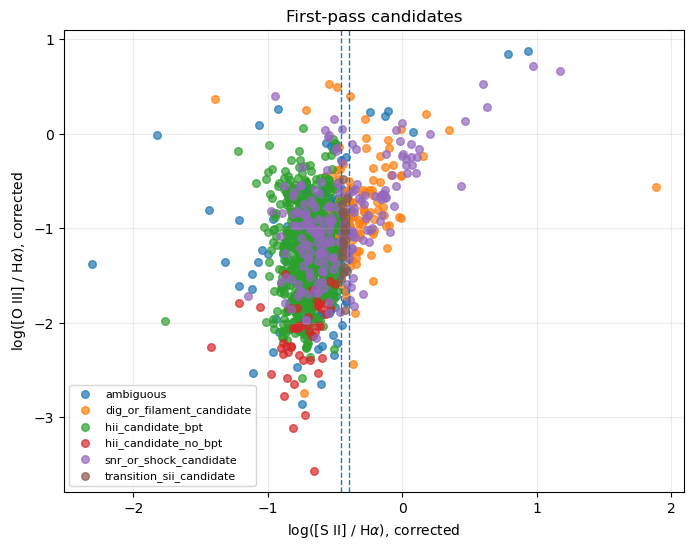

In [32]:
plot_cat = cat2[
    np.isfinite(cat2["log_sii_ha_corr"])
    & np.isfinite(cat2["log_oiii_ha_corr"])
].copy()

plt.figure(figsize=(8, 6))
for tag, subset in plot_cat.groupby("first_pass_tag"):
    plt.scatter(
        subset["log_sii_ha_corr"],
        subset["log_oiii_ha_corr"],
        s=30,
        alpha=0.7,
        label=tag,
    )

plt.axvline(np.log10(SII_HA_HII_MAX), linestyle="--", linewidth=1)
plt.axvline(np.log10(SII_HA_SHOCK_MIN), linestyle="--", linewidth=1)
plt.xlabel(r"log([S II] / H$\alpha$), corrected")
plt.ylabel(r"log([O III] / H$\alpha$), corrected")
plt.title("First-pass candidates")
plt.legend(fontsize=8)
plt.grid(alpha=0.25)
plt.show()


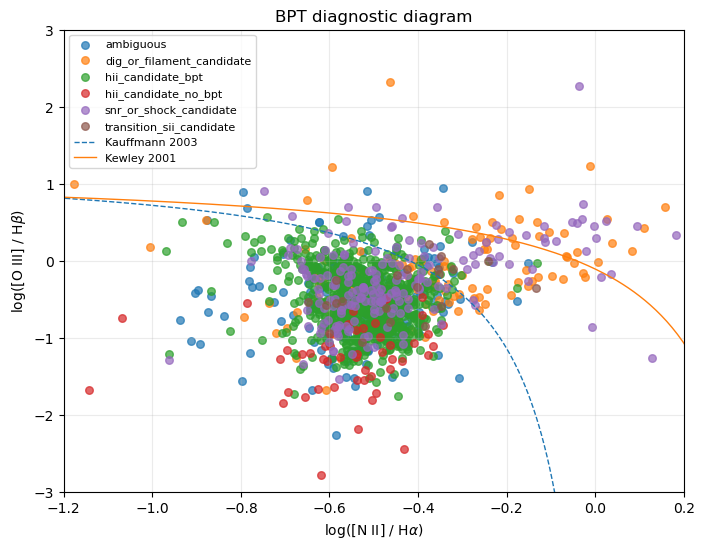

In [33]:
plot_cat = cat2[
    np.isfinite(cat2["log_nii_ha_corr"])
    & np.isfinite(cat2["log_oiii_hb_corr"])
].copy()

x = np.linspace(-2.0, 0.45, 400)
kauffmann_x = x[x < 0.05]
kauffmann_y = 0.61 / (kauffmann_x - 0.05) + 1.30
kewley_x = x[x < 0.47]
kewley_y = 0.61 / (kewley_x - 0.47) + 1.19

plt.figure(figsize=(8, 6))
for tag, subset in plot_cat.groupby("first_pass_tag"):
    plt.scatter(
        subset["log_nii_ha_corr"],
        subset["log_oiii_hb_corr"],
        s=30,
        alpha=0.7,
        label=tag,
    )

plt.plot(kauffmann_x, kauffmann_y, "--", linewidth=1, label="Kauffmann 2003")
plt.plot(kewley_x, kewley_y, "-", linewidth=1, label="Kewley 2001")
plt.xlim(-1.2, 0.2)
plt.ylim(-3, 3)
plt.xlabel(r"log([N II] / H$\alpha$)")
plt.ylabel(r"log([O III] / H$\beta$)")
plt.title("BPT diagnostic diagram")
plt.legend(fontsize=8)
plt.grid(alpha=0.25)
plt.show()


In [34]:
sn_ha_map = ha / ha_err
sn_oiii_map = oiii / oiii_err
sn_sii_map = sii / sii_err

log_sii_ha_map = safe_log10_ratio(sii, ha)
log_oiii_ha_map = safe_log10_ratio(oiii, ha)

MAP_SN_MIN = 2.0
log_sii_ha_map[(sn_sii_map < MAP_SN_MIN) | (sn_ha_map < MAP_SN_MIN)] = np.nan
log_oiii_ha_map[(sn_oiii_map < MAP_SN_MIN) | (sn_ha_map < MAP_SN_MIN)] = np.nan


In [35]:
def inspect_regions(tag, n=5, pad=50):
    region_ids = cat2.loc[
        cat2["first_pass_tag"] == tag,
        "region_id",
    ].head(n)

    for region_id in region_ids:
        source_crop, annulus_crop, slc = make_local_annulus(
            labels_data,
            region_id,
            qa_lookup,
            label_slices,
            ANNULUS_INNER_FACTOR,
            ANNULUS_OUTER_FACTOR,
        )

        row = cat2.loc[cat2["region_id"] == region_id].iloc[0]
        print(
            f"Region {region_id} | {tag} | "
            f"[SII]/Ha={row['sii_ha_corr']:.2f} | "
            f"[OI]/Ha={row['oi_ha_corr']:.2f} | "
            f"Ha contrast={row['ha_contrast']:.2f}"
        )

        show_source_annulus(
            percentile_norm(detection),
            source_crop,
            annulus_crop,
            slc,
            labels_data=labels_data,
            title=f"Region {region_id}: detection",
            pad=pad,
        )

        show_source_annulus(
            log_sii_ha_map,
            source_crop,
            annulus_crop,
            slc,
            labels_data=labels_data,
            title=f"Region {region_id}: log([S II]/Hα)",
            pad=pad,
        )


Region 2 | snr_or_shock_candidate | [SII]/Ha=0.21 | [OI]/Ha=0.13 | Ha contrast=43.06


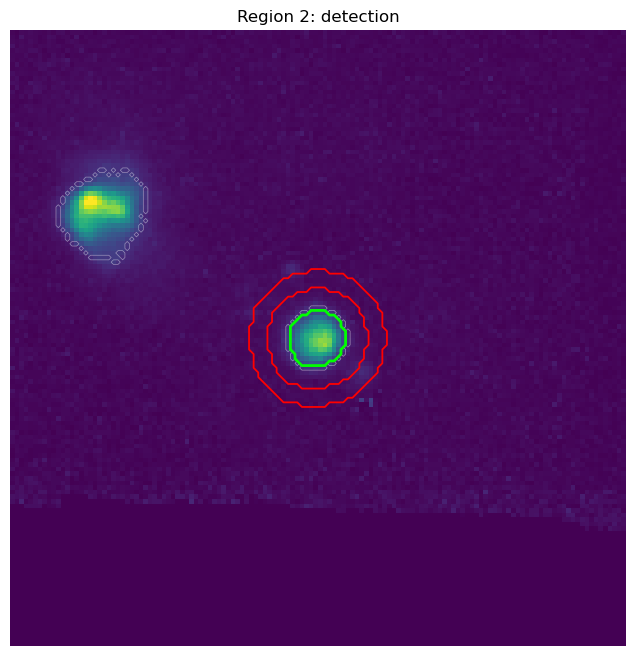

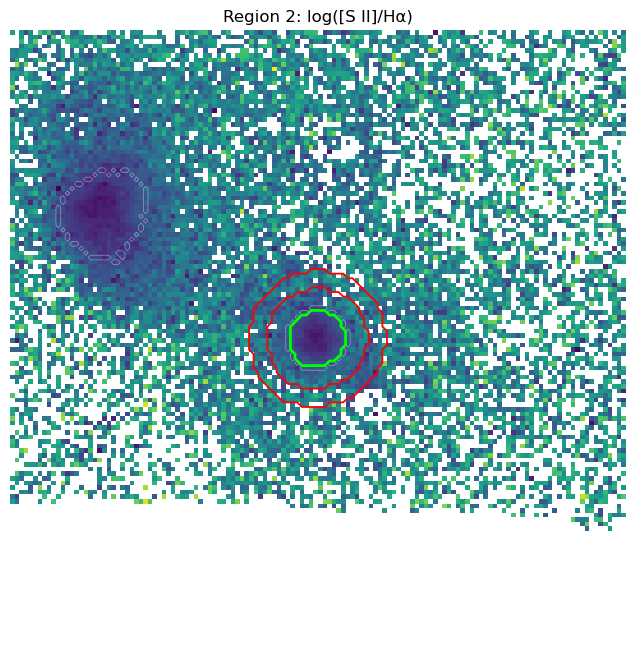

Region 3 | snr_or_shock_candidate | [SII]/Ha=0.18 | [OI]/Ha=0.08 | Ha contrast=31.08


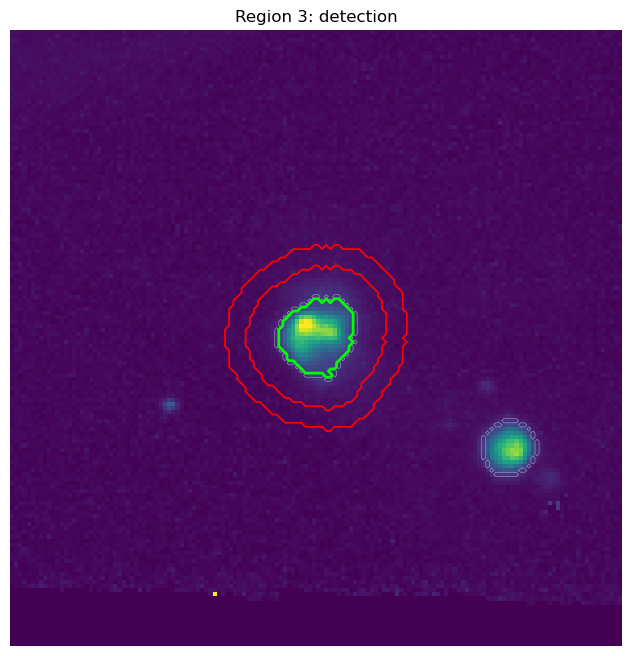

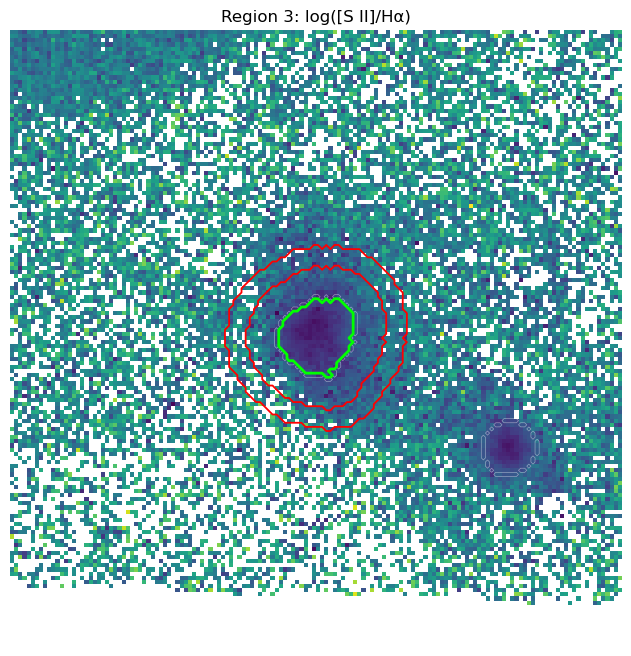

Region 4 | snr_or_shock_candidate | [SII]/Ha=0.22 | [OI]/Ha=0.36 | Ha contrast=35.73


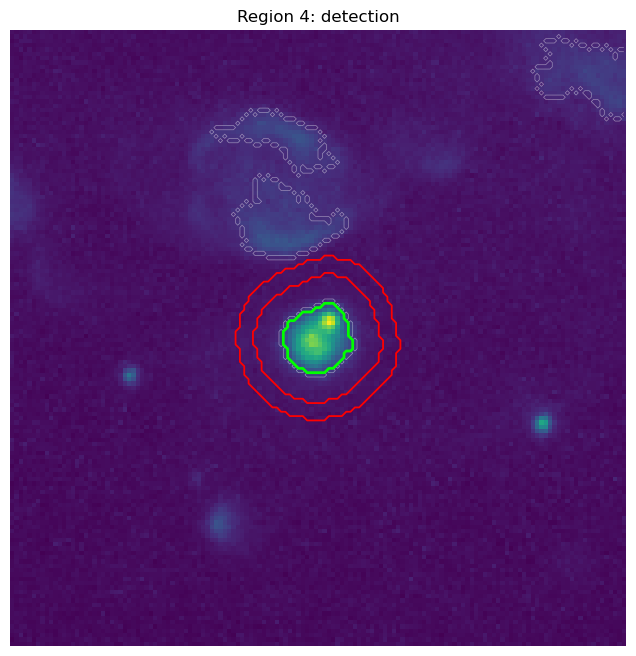

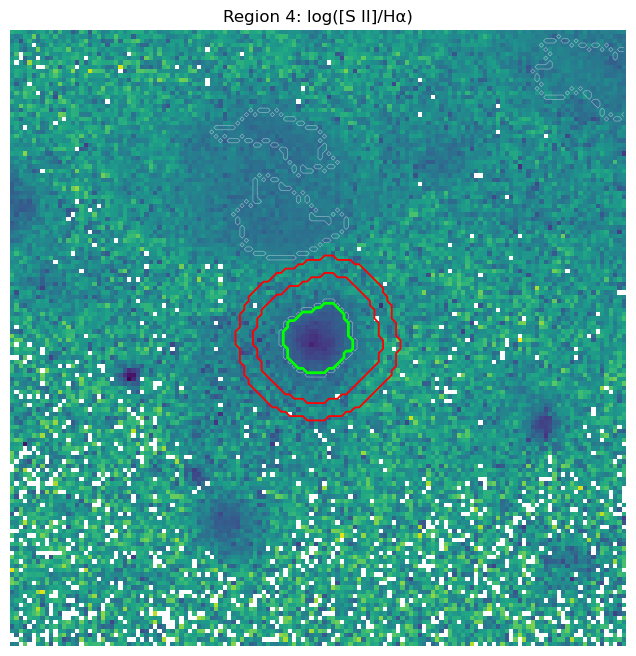

Region 6 | snr_or_shock_candidate | [SII]/Ha=0.24 | [OI]/Ha=0.21 | Ha contrast=8.92


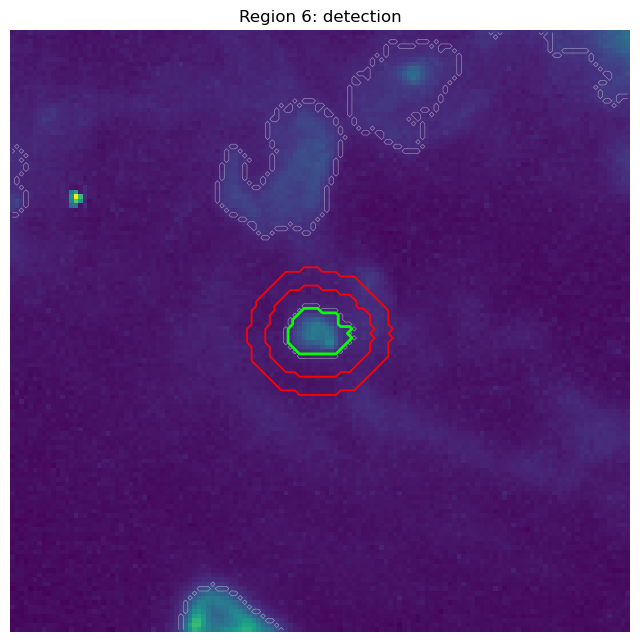

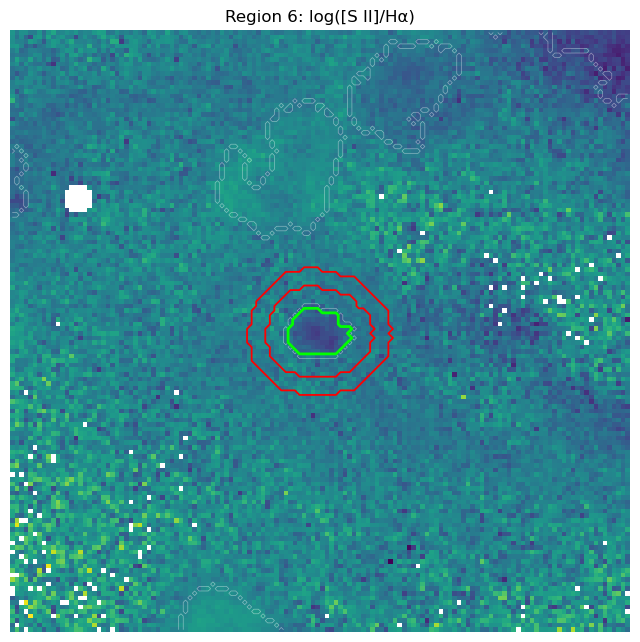

Region 9 | snr_or_shock_candidate | [SII]/Ha=0.31 | [OI]/Ha=0.10 | Ha contrast=12.04


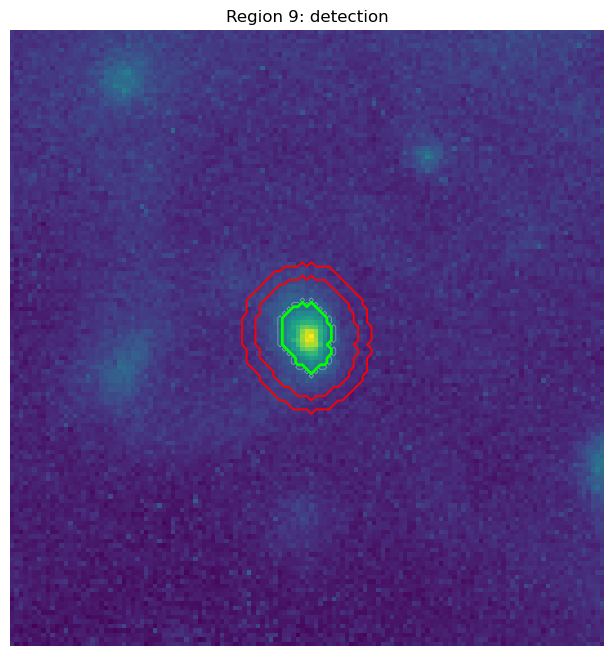

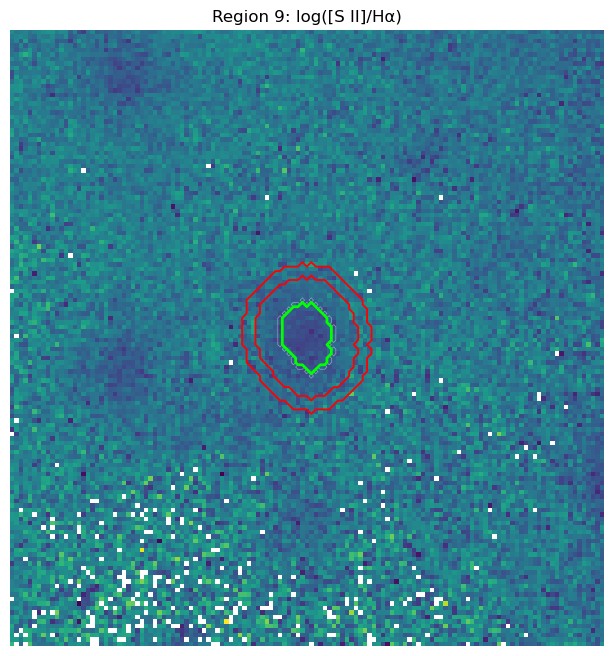

In [36]:
# Change the tag or number as needed.
inspect_regions("snr_or_shock_candidate", n=5)


## 16. Save catalogue and maps

In [40]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

cat2.to_pickle(OUTPUT_DIR / "first_pass_catalog.pkl")
cat2.to_csv(OUTPUT_DIR / "first_pass_catalog.csv", index=False)
qa2.to_pickle(OUTPUT_DIR / "qa_catalog.pkl")
flux_cat.to_pickle(OUTPUT_DIR / "flux_catalog.pkl")
segmentation_summary.to_csv(OUTPUT_DIR / "segmentation_summary.csv", index=False)

seg_header = header.copy()
seg_header["BUNIT"] = "label"
seg_header["COMMENT"] = "0 = background; positive integers = region IDs"

fits.writeto(
    OUTPUT_DIR / "labels_photutils.fits",
    labels_photutils.astype(np.int32),
    seg_header,
    overwrite=True,
)
fits.writeto(
    OUTPUT_DIR / "labels_data.fits",
    labels_data.astype(np.int32),
    seg_header,
    overwrite=True,
)
fits.writeto(
    OUTPUT_DIR / "detection.fits",
    detection.astype(np.float32),
    header,
    overwrite=True,
)

line_products = {
    "ha": ha,
    "ha_err": ha_err,
    "hb": hb,
    "hb_err": hb_err,
    "oiii": oiii,
    "oiii_err": oiii_err,
    "nii": nii,
    "nii_err": nii_err,
    "sii": sii,
    "sii_err": sii_err,
    "oi": oi,
    "oi_err": oi_err}

for name, arr in line_products.items():
    fits.writeto(
        OUTPUT_DIR / f"{name}.fits",
        arr.astype(np.float32),
        header,)

metadata = {
    "input_fits_path": str(DATA_FITS),
    "selected_segmentation_run": selected_run,
    "selected_segmentation_params": selected_segmentation_params,
    "tested_segmentation_runs": segmentation_summary.to_dict(orient="records"),
    "n_final_regions": int(count_regions(labels_data)),
    "boundary_flux_fraction": BOUNDARY_FLUX_FRACTION,
    "boundary_annulus_width": BOUNDARY_ANNULUS_WIDTH,
    "annulus_inner_factor": ANNULUS_INNER_FACTOR,
    "annulus_outer_factor": ANNULUS_OUTER_FACTOR,
    "min_annulus_pix": MIN_ANNULUS_PIX,
    "line_sn_min": LINE_SN_MIN,
    "ha_contrast_min": HA_CONTRAST_MIN,
    "sii_ha_hii_max": SII_HA_HII_MAX,
    "sii_ha_shock_min": SII_HA_SHOCK_MIN,
    "oi_ha_shock_min": OI_HA_SHOCK_MIN,
    "pix_scale_arcsec": pix_scale,
    "psf_fwhm_arcsec": psf_fwhm_arcsec,
}

with open(OUTPUT_DIR / "metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("Saved to:", OUTPUT_DIR.resolve())


Saved to: /Users/golta/Desktop/Uni/Thesis/Model Selection/Classic_v4.0/results_photutils
